# Авторское меню настоек

**Какие настойки включить в меню и сколько сырья потребуется на два вечера?**

Проект соединяет исследование публичных отзывов о барах Санкт-Петербурга с авторским выбором десяти напитков. Результат — [готовое меню PDF](results/nastoyka_menu.pdf), общая закупка и сырьевая экономика для 60 л.

В публичной версии сохранены исходные отзывы и готовые экономические выгрузки. Здесь можно повторить анализ отзывов и итоговые агрегаты; пересчёт по закрытым рецептурам недоступен. Все денежные результаты относятся к сценарию 16.10.2026, а не к фактическим продажам.

## 1. Данные и правила анализа

Источники — открытые отзывы, меню и страницы заведений. В [Excel](data/nastoyki_reviews.xlsx) сохранены связи «заведение → отзыв → упоминание», ссылки и статусы проверки. [Методика](docs/methodology.md) описывает нормализацию и ограничения.

In [1]:
from pathlib import Path
from decimal import Decimal as D
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from scripts.portfolio import ROOT, read_csv, research_summary, economics_summary, number, fmt

stats = research_summary()
menu = read_csv("data/menu_economics.csv")
purchases = read_csv("data/menu_raw_material_costs.csv")
flavors = pd.read_csv(ROOT / "data/flavor_summary.csv", encoding="utf-8-sig")
summary = economics_summary()
def show(headers, rows):
    text = "| "+" | ".join(headers)+" |\n| "+" | ".join(["---"]*len(headers))+" |\n"
    text += "\n".join("| "+" | ".join(str(v).replace("|"," / ") for v in row)+" |" for row in rows)
    display(Markdown(text))
show(["База исследования", "Число наблюдений"], [
    ["Карточки заведений / актуальный срез", str(stats["venues_total"])+" / "+str(stats["current_sample"])],
    ["Публикации / проверенные", str(stats["reviews_total"])+" / "+str(stats["reviews_verified"])],
    ["Конкретные упоминания / отзывы", str(stats["concrete_mentions"])+" / "+str(stats["concrete_reviews"])],
    ["Нормализованные проверенные вкусы", stats["flavors"]],
    ["Строгий срез: упоминания / отзывы", str(stats["strict_mentions"])+" / "+str(stats["strict_reviews"])],
])

| База исследования | Число наблюдений |
| --- | --- |
| Карточки заведений / актуальный срез | 43 / 30 |
| Публикации / проверенные | 368 / 358 |
| Конкретные упоминания / отзывы | 198 / 108 |
| Нормализованные проверенные вкусы | 114 |
| Строгий срез: упоминания / отзывы | 143 / 84 |

Один отзыв может содержать несколько вкусов. Явные синонимы объединены, разные сочетания ингредиентов сохранены отдельно. Пять звёзд заведению и перечень заказанного не считаются положительной оценкой каждого напитка.

Неподтверждённые записи сохранены, но исключены из проверенной базы. Строгий срез дополнительно ограничен выбранными заведениями, высокой уверенностью и признаками качества публикаций.

## 2. Что показали отзывы

Посмотрим на свидетельства для вкусов будущего меню. Рядом с частотой нужны число отзывов и число заведений: много упоминаний в одном баре не означает популярность во всём городе.

| Вкус | Упоминания | Отзывы | Заведения | Положительные оценки* |
| --- | --- | --- | --- | --- |
| Хреновуха | 7 | 7 | 6 | 5 |
| Вишня | 4 | 4 | 4 | 3 |
| Малина | 6 | 6 | 3 | 4 |
| Лимончелло | 4 | 4 | 4 | 4 |
| Щавель | 7 | 7 | 3 | 5 |
| Яблоко — базилик | 3 | 3 | 1 | 3 |
| Облепиха | 3 | 3 | 3 | 1 |
| Клюква | 3 | 3 | 2 | 0 |
| Халва | 6 | 6 | 3 | 5 |
| Малина — сливки | 2 | 2 | 1 | 2 |

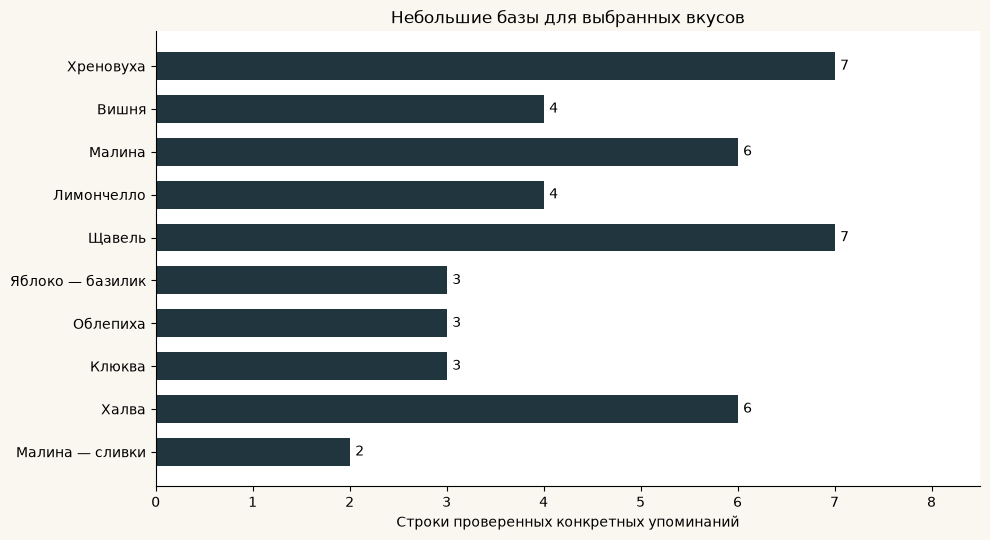

In [2]:
selected = flavors.set_index("Вкус").loc[[r["normalized_flavor"] for r in menu]]
show(["Вкус", "Упоминания", "Отзывы", "Заведения", "Положительные оценки*"], [
    [name, int(row["Проверенные упоминания"]), int(row["Уникальные отзывы"]), int(row["Заведения"]), int(row["Положительные"])]
    for name, row in selected.iterrows()
])
with plt.rc_context({"font.family":"DejaVu Sans"}):
    fig, ax = plt.subplots(figsize=(10,5.5), facecolor="#FAF7F0")
    values = selected["Проверенные упоминания"]
    bars = ax.barh(selected.index, values, color="#21353F", height=.65)
    ax.bar_label(bars, padding=4)
    ax.invert_yaxis(); ax.set(xlabel="Строки проверенных конкретных упоминаний", title="Небольшие базы для выбранных вкусов", xlim=(0,values.max()+1.5))
    ax.spines[["top","right"]].set_visible(False)
    fig.tight_layout(); display(fig); plt.close(fig)

\* Положительные оценки ограничены одним голосом на вкус в рамках отзыва/общего события. Поэтому это не независимые посетители и не обязательно та же база, что число строк упоминаний.

У хреновухи и щавеля — по **7 упоминаний и 5 положительных оценок**. Они заметны в этой выборке, но базы малы. Пример концентрации — простая томатная: шесть положительных упоминаний из одного заведения, в строгом срезе одно. Редкость вкуса тоже не доказывает спрос.

У 275 из 358 проверенных публикаций доступен только видимый фрагмент. Отзывы исторические; посетители, которые пишут отзывы, не представляют всех гостей. Демографических данных недостаточно для сравнения групп.

## 3. Как сформировано авторское меню

Исследование помогло изучить конкурентный ассортимент и составить варианты. Финальные десять вкусов, их рецептуры и цены согласовал автор. **Это авторское решение, а не автоматически доказанный оптимум.**

Восемь основных позиций стоят 250 ₽, две премиальные — 300 ₽ за 50 мл. Такое разделение — ценовая архитектура автора. Клюква оставлена в меню при отсутствии подтверждённых положительных оценок в текущих отзывах.

## 4. Готовое меню

PDF предназначен для отдельного просмотра или отправки гостю. Краткие описания указывают ингредиенты, а не результаты нового дегустационного теста. Дозировки и технология приготовления не раскрываются.

[Открыть PDF](results/nastoyka_menu.pdf) · [Открыть PNG](results/menu_preview.png)

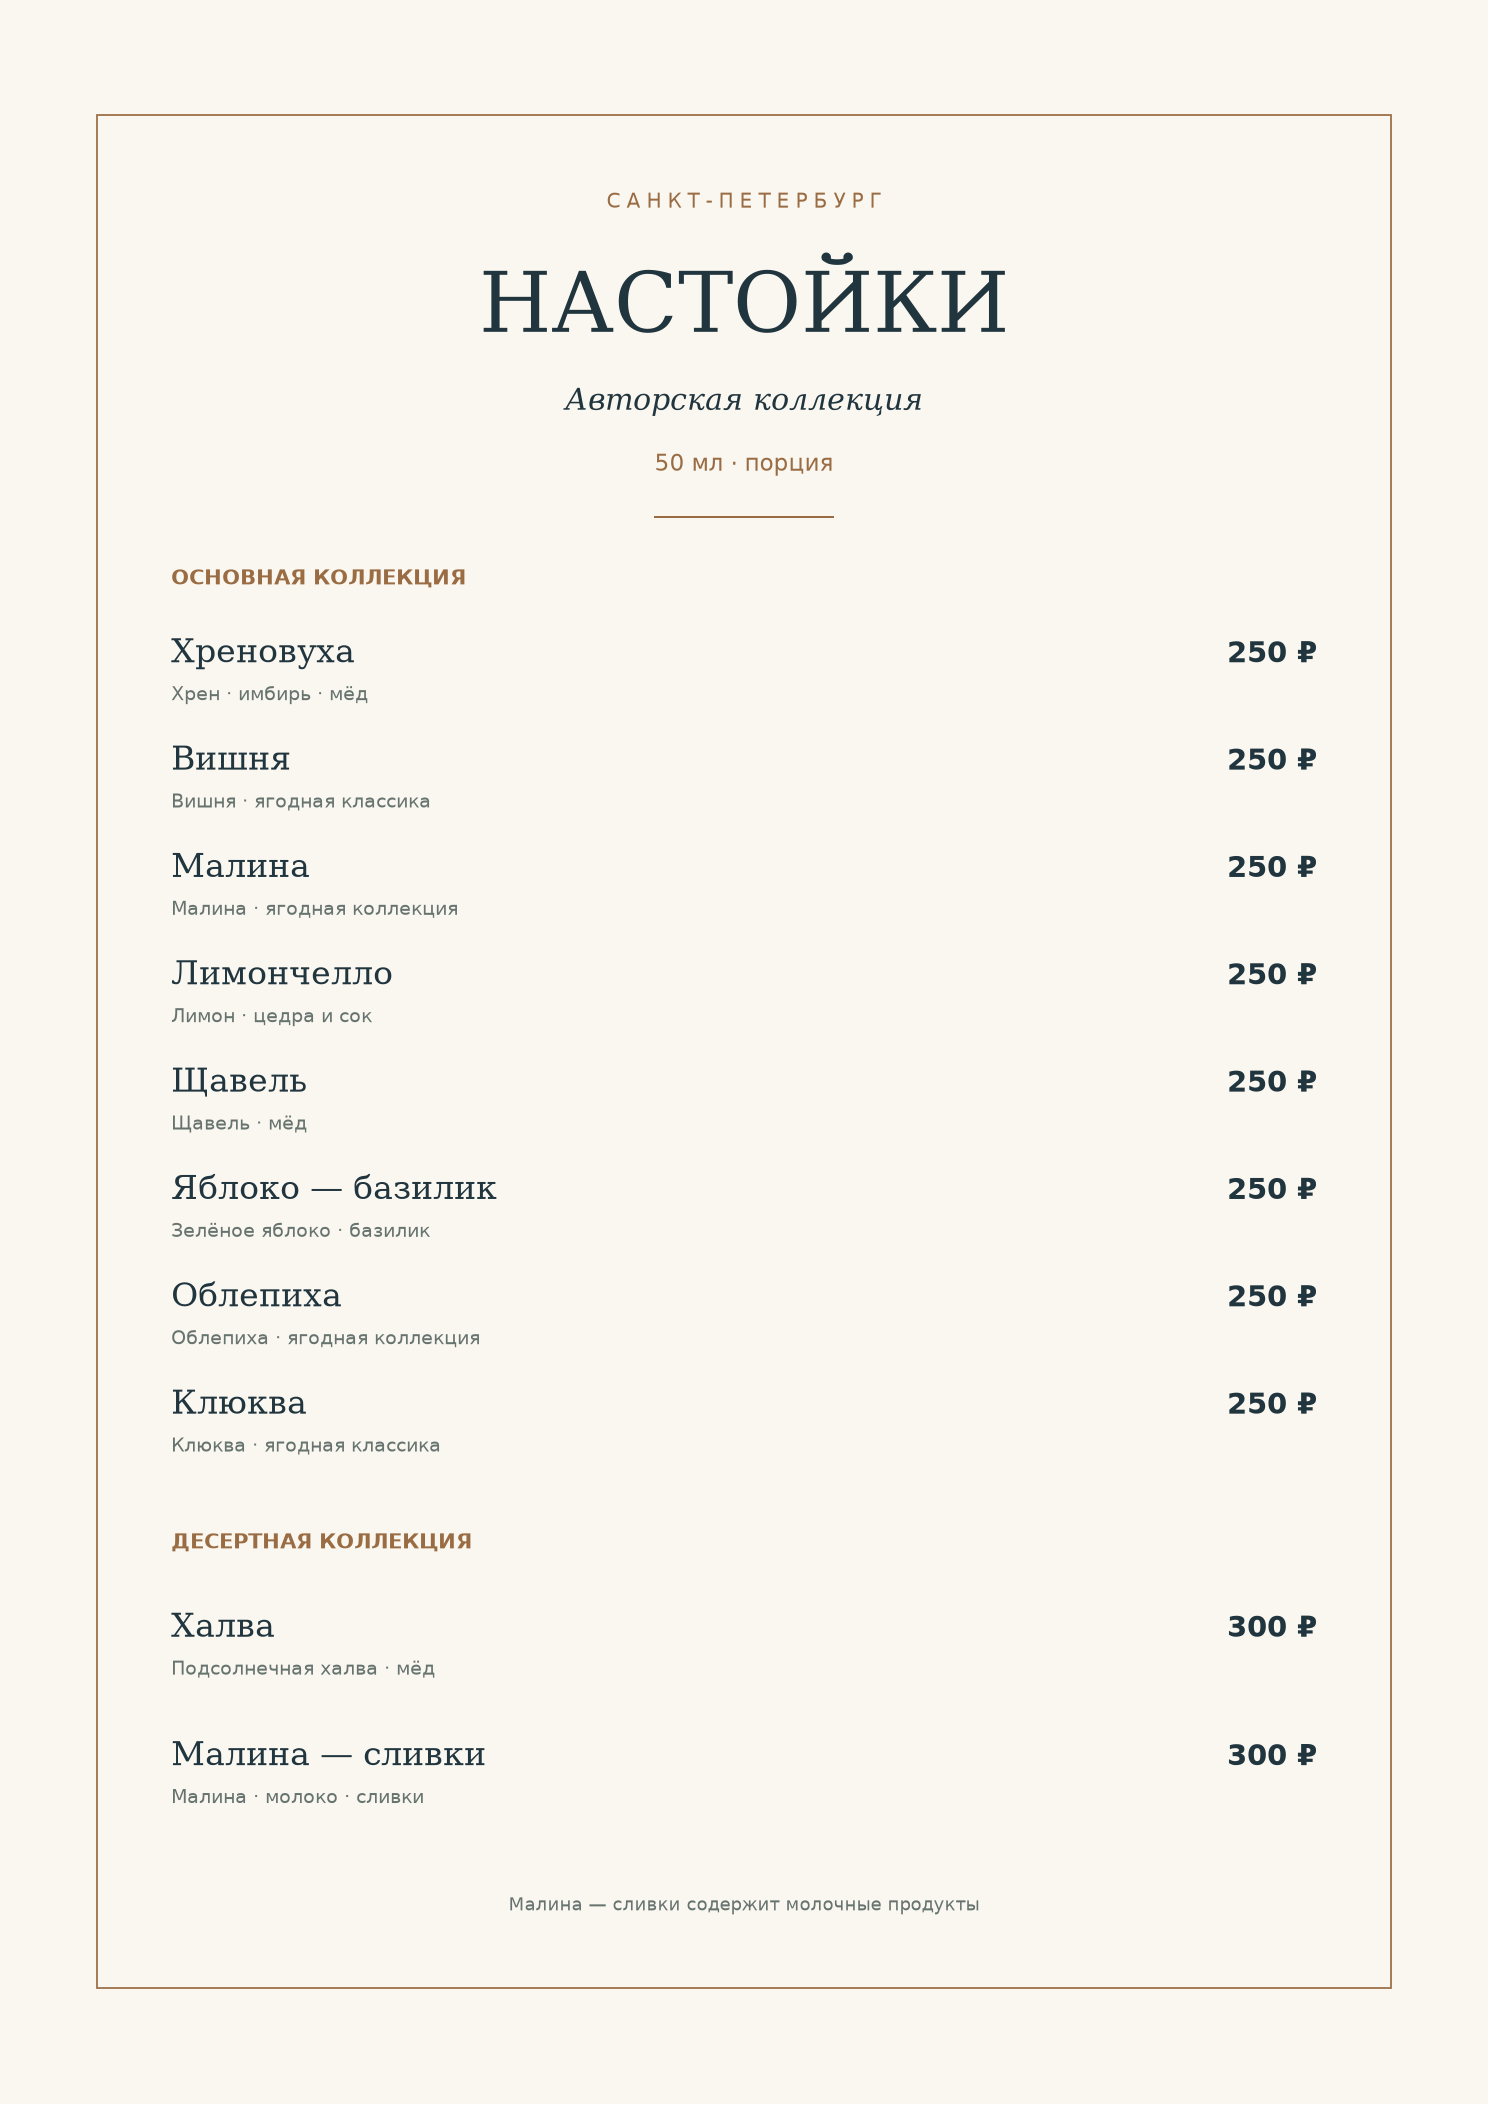

In [3]:
display(Image(filename=str(ROOT / "results/menu_preview.png"), width=650))

## 5. Общая закупка сырья

План — по **6 л каждого вкуса**, 120 порций: по 60 на пятницу и субботу. Всего 60 л и 1 200 порций. Дата запуска не назначена.

В завершённой модели потребность одинакового сырья сначала складывалась по всему меню, затем округлялась до упаковок. Ниже — сохранённая общая закупка, без распределения ингредиентов по отдельным напиткам.

In [4]:
show(["Сырьё", "Нужно", "Ед.", "Заказ, ₽", "В партии, ₽", "Запас, ₽"], [
    [r["Сырьё"], r["Плановая потребность"], r["Единица"], r["Закупка, ₽"], r["Израсходованное сырьё, ₽"], r["Остаток сырья, ₽"]]
    for r in purchases
])
supplier_totals = {}
for row in purchases:
    supplier_totals[row["Поставщик"]] = supplier_totals.get(row["Поставщик"], D(0)) + number(row["Закупка, ₽"])
show(["Поставщик", "Первая закупка, ₽"], [[name,fmt(value)] for name,value in supplier_totals.items()])

| Сырьё | Нужно | Ед. | Заказ, ₽ | В партии, ₽ | Запас, ₽ |
| --- | --- | --- | --- | --- | --- |
| Водка Царская Оригинальная 40% | 47,301 | л | 18 240,00 | 17 974,27 | 265,73 |
| Вишня замороженная без косточек | 2,174 | кг | 2 397,00 | 1 736,96 | 660,04 |
| Малина замороженная | 5,218 | кг | 5 994,00 | 5 213,27 | 780,73 |
| Облепиха замороженная | 4,167 | кг | 1 995,00 | 1 662,50 | 332,50 |
| Клюква замороженная | 3,582 | кг | 2 076,00 | 1 859,10 | 216,90 |
| Лимоны целые | 7,600 | кг | 1 432,00 | 1 360,40 | 71,60 |
| Щавель свежий | 1,132 | кг | 1 668,00 | 1 573,58 | 94,42 |
| Базилик зелёный свежий | 0,138 | кг | 447,00 | 412,62 | 34,38 |
| Сахар | 9,711 | кг | 729,00 | 707,92 | 21,08 |
| Мёд | 2,460 | кг | 987,00 | 809,25 | 177,75 |
| Халва подсолнечная | 8,000 | кг | 1 500,80 | 1 500,80 | 0,00 |
| Сливки 10% | 1,286 | л | 398,00 | 255,86 | 142,14 |
| Молоко 3.2% | 1,286 | л | 158,00 | 101,57 | 56,43 |
| Хрен: свежий необработанный корень | 1,213 | кг | 1 306,00 | 791,94 | 514,06 |
| Имбирь свежий | 0,191 | кг | 330,00 | 63,19 | 266,81 |
| Яблоки зелёные свежие | 4,846 | кг | 345,00 | 334,38 | 10,62 |

| Поставщик | Первая закупка, ₽ |
| --- | --- |
| Ладога | 18 240,00 |
| METRO | 19 781,80 |
| Агропарк СПб | 1 981,00 |

[Полная таблица закупок](data/menu_raw_material_costs.csv) содержит фасовки, количество упаковок, цену и физический остаток. Количества округлены для отображения; цены соответствуют авторскому сценарию.

**Закупка и производственный расход различаются.** Поставщику оплачиваются целые упаковки. Неиспользованное сырьё остаётся в запасе; его пригодность для следующей партии зависит от условий хранения и потребности.

## 6. Сырьевая себестоимость

Итоговые затраты взяты из проверенной модели и сохранены с высокой точностью. Для просмотра деньги округлены до двух знаков. В публичных данных нет состава партий, поэтому восстановить весь исходный расчёт по этим строкам нельзя.

| Настойка | Цена 50 мл, ₽ | Сырьё 50 мл, ₽ | Сырьё 6 л, ₽ |
| --- | --- | --- | --- |
| Хреновуха | 250,00 | 27,69 | 3 322,66 |
| Вишня | 250,00 | 29,56 | 3 547,61 |
| Малина | 250,00 | 37,08 | 4 449,53 |
| Лимончелло | 250,00 | 25,22 | 3 026,20 |
| Щавель | 250,00 | 34,14 | 4 096,98 |
| Яблоко — базилик | 250,00 | 21,29 | 2 554,68 |
| Облепиха | 250,00 | 27,55 | 3 306,58 |
| Клюква | 250,00 | 30,49 | 3 658,52 |
| Халва | 300,00 | 36,91 | 4 428,93 |
| Малина — сливки | 300,00 | 33,05 | 3 965,91 |

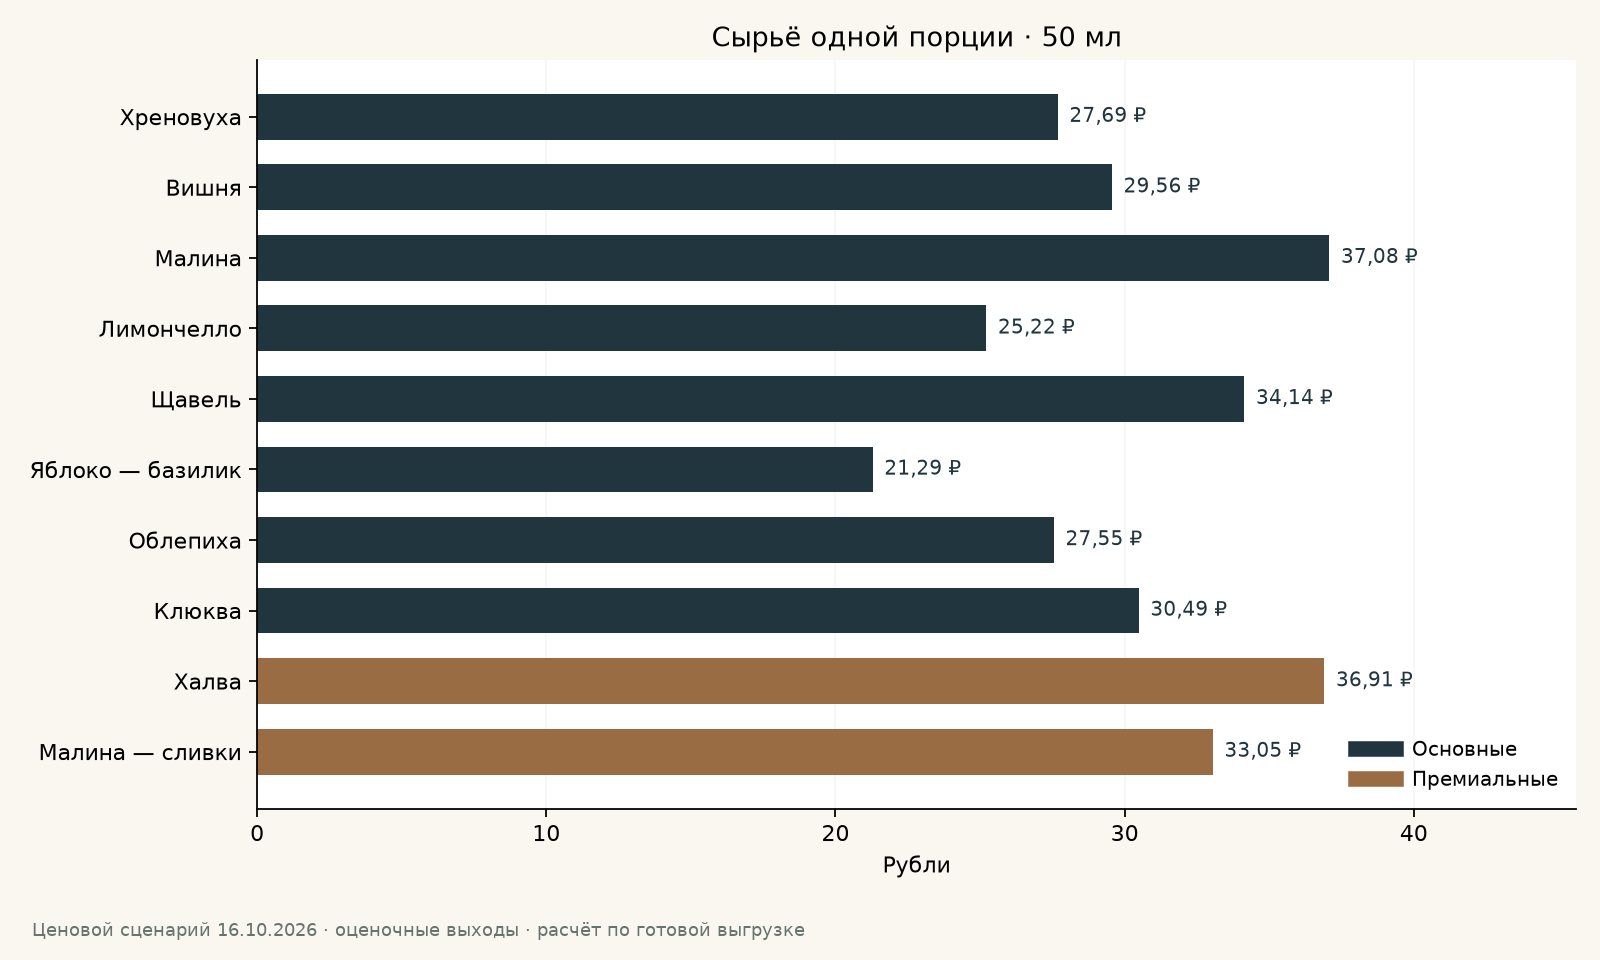

In [5]:
show(["Настойка", "Цена 50 мл, ₽", "Сырьё 50 мл, ₽", "Сырьё 6 л, ₽"], [
    [r["normalized_flavor"],fmt(r["price_50ml_rub"]),fmt(r["cost_50ml_rub"]),fmt(r["used_cost_rub"])]
    for r in menu
])
display(Image(filename=str(ROOT / "results/cost_50ml.png")))

Яблоко — базилик имеет наименьший сырьевой расход на порцию в этом сценарии, малина — наибольший. Премиальная цена халвы и малины — сливок остаётся решением автора: сама себестоимость не доказывает готовность гостя платить.

## 7. Потенциальная выручка и итоговые суммы

При продаже всех порций выручка равна цене каждого вкуса, умноженной на его плановые 120 порций. Это сценарий полной реализации, не наблюдавшиеся продажи.

In [6]:
show(["Показатель", "Плановый сценарий"], [
    ["Готовые напитки",fmt(summary["ready_liters"],0)+" л"],
    ["Порции по 50 мл",fmt(summary["portions"],0)],
    ["Первоначальная закупка",fmt(summary["purchase_rub"])+" ₽"],
    ["Использованное сырьё",fmt(summary["used_rub"])+" ₽"],
    ["Остаток сырья",fmt(summary["leftover_rub"])+" ₽"],
    ["Потенциальная выручка",fmt(summary["revenue_rub"])+" ₽"],
    ["Доход после израсходованного сырья",fmt(summary["material_contribution_rub"])+" ₽"],
])
print("Среднее сырьё одной порции:",fmt(summary["used_rub"]/summary["portions"]),"₽")

| Показатель | Плановый сценарий |
| --- | --- |
| Готовые напитки | 60 л |
| Порции по 50 мл | 1 200 |
| Первоначальная закупка | 40 002,80 ₽ |
| Использованное сырьё | 36 357,61 ₽ |
| Остаток сырья | 3 645,19 ₽ |
| Потенциальная выручка | 312 000,00 ₽ |
| Доход после израсходованного сырья | 275 642,39 ₽ |

Среднее сырьё одной порции: 30,30 ₽


Средние **30,30 ₽** сырья на 50 мл не означают чистую прибыль. При неполной продаже выручка снижается, а уже израсходованное на производство сырьё не возвращается. Равный выпуск десяти вкусов не гарантирует равного спроса.

## 8. Главные выводы

**Получено готовое авторское меню.** Десять вкусов объединены в две ценовые группы; меню PDF и общая закупочная ведомость доступны отдельно.

**Отзывы дали контекст выбора, а не прогноз продаж.** У хреновухи и щавеля по пять положительных оценок, но небольшие базы и концентрация по заведениям ограничивают выводы. Клюква включена решением автора.

**Для 60 л требуется 40 002,80 ₽ на сырьевую закупку.** В партии используется сырьё на 36 357,61 ₽; разница остаётся в запасе. Потенциальная выручка 312 000 ₽ требует полной реализации всех 1 200 порций.

Результат можно использовать для обсуждения ассортимента и подготовки общей закупки. Перед заказом необходимо подтвердить цены и наличие. Выходы оценочные; безопасный срок хранения молочной настойки не установлен. Новые рецептуры, исследования и дополнительные виды расходов в этом этапе не добавлялись.

Публичная часть повторяет анализ доступных данных и сборку материалов. Полный рецептурный пересчёт остаётся вне этой версии; [методика](docs/methodology.md) объясняет границы воспроизведения.